# Did the 20% + 4 A-grade cap change what Harvard students enrol in?

Harvard FAS will apply a **20% + 4** cap on A grades from **Fall 2027** — instructors may award
A's to at most 20% of undergraduate enrolment plus four, with **A- and every other grade
uncapped**. The proposal became public in **February 2026**, the faculty adopted it by ballot
**458–201 on 20 May 2026**, and a set of large introductory courses (CS 50, Life Sciences 1a,
Ec 10a/b, Hum 10, Psych 1, Expos, intro Maths) began complying voluntarily in **Fall 2026**.

This notebook asks whether that shows up in registrar enrolment data. It tests six hypotheses
that circulated among students, plus pre-med and "iconic course" cuts, and it looks for changes
nobody predicted.

**Comparisons**

| | treated term | control term |
|---|---|---|
| Announcement effect | Spring 2026 | Spring 2025 |
| Early-enforcement effect | Fall 2026 | Fall 2025 |

Four earlier terms per season (2022-2024, pulled from the FAS Registrar archive) provide a
**pre-trend baseline**, so a 2026 change can be judged against normal year-to-year variation
rather than taken at face value.

**Hypotheses**

1. Students pile into Gen Ed courses.
2. Students shift toward seminars and small classes.
3. Students take harder courses.
4. Students take graduate courses, where grading is thought to be easier.
5. Students avoid departments already enforcing the cap, especially Computer Science.
6. Pre-med requirement courses and Harvard's iconic large courses move.

**The headline: most of these do not survive contact with a baseline.** Details in the
findings section at the end.

## 1. Setup

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, ".")

import pandas as pd
import numpy as np
import enrollment_lib as E          # loader + taxonomy, kept beside this notebook

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

FALLS   = ["F22", "F23", "F24", "F25", "F26"]
SPRINGS = ["S22", "S23", "S24", "S25", "S26"]
ORDER   = ["S22", "F22", "S23", "F23", "S24", "F24", "S25", "F25", "S26", "F26"]

FALL_PAIRS   = [("F22","F23"), ("F23","F24"), ("F24","F25"), ("F25","F26")]
SPRING_PAIRS = [("S22","S23"), ("S23","S24"), ("S24","S25"), ("S25","S26")]

d = E.classify(E.load_all("."))
d["course"] = d.subject + " " + d.catalog.fillna("")
print(f"{len(d):,} section rows across {d.term.nunique()} terms")

29,766 section rows across 10 terms


## 2. Data provenance and the four things that would fool us

The four 2025-26 files are the user's. The six 2022-24 files were downloaded from the
[FAS Registrar enrolment-report archive](https://registrar.fas.harvard.edu/links/archive/enrollment-reports)
and converted from `.xlsx`; each was checksum-verified after conversion.

Four traps are worth naming before any number is read.

### Trap 1 — the snapshot dates are not aligned

Each report is a point-in-time pull, and the pull dates move around by up to two months.

In [2]:
prov = (d.groupby("term", observed=True)
          .agg(pulled=("run_date", "first"), sections=("Class Number", "size"),
               ugrad=("UGrad", "sum"), grad=("Grad", "sum"), withdrew=("Withdraw", "sum"))
          .reindex(ORDER))
prov

,pulled,sections,ugrad,grad,withdrew
term,,,,,
S22,2022-03-22,2891,27520,8295,29
F22,2022-12-12,2865,28715,9280,191
S23,2023-05-17,2946,28253,8438,182
F23,2023-12-18,2968,28572,9323,127
S24,2024-03-19,3059,28377,8379,24
F24,2024-11-05,3024,28830,9348,29
S25,2025-03-26,3031,28401,8439,26
F25,2025-10-31,3048,27628,9479,37
S26,2026-03-24,3057,27001,8182,35


**Consequence.** Fall 2026 was pulled 15 Sep, six weeks earlier in the term than Fall 2025
(31 Oct). Withdrawals accumulate through a term, so the fall `Withdraw` counts (37 vs 2) compare
nothing at all — **withdrawals are excluded from every Fall 2025 → 2026 claim below.**

Enrolment counts are safe: registration closes in the first week, and withdrawals are a rounding
error against enrolment (37 out of 38,733 in Fall 2025, under 0.1%), so an early pull barely moves
the `UGrad` column.

The Spring pair *is* aligned — 26 Mar 2025 vs 24 Mar 2026 — so withdrawals are analysed there.
Spring 2023 (17 May, end of term) is excluded from the withdrawal series for the same reason.

### Trap 2 — headcounts move, so use shares

Total College enrolments drift between terms. Every measure below is a **share of that term's
undergraduate enrolments**, or a same-course comparison — never a raw count across terms.

### Trap 3 — the registrar renamed things mid-window

Left alone, each rename reads as a department losing all of its students while an identical
one appears from nowhere. `enrollment_lib` folds them back together.

In [3]:
print("subject codes:"); [print("  ", k, "->", v) for k, v in E.SUBJECT_ALIASES.items()]
print("department labels:"); [print("  ", k, "->", v) for k, v in E.DEPT_ALIASES.items()]

subject codes:
   FRSEMR -> FYSEMR
   HSEMR-EL -> FYSEMR
   HSEMR-LE -> FYSEMR
   AAAS -> AFRAMER
   ECE -> ENG-SCI
department labels:
   Human Evolutionary Biology -> Human Biology, Behavior,& Evol
   Freshman Seminars -> First Year Seminar Program
   Biological and Biomedical Scie -> Medical Sciences
   Biomedical Informatics -> Medical Sciences
   Immunology -> Medical Sciences
   Speech and Hearing Bioscience -> Medical Sciences
   Virology -> Medical Sciences
   Electrical and Computer Engine -> Engineering Sciences


[None, None, None, None, None, None, None, None]

The consequential ones:

* `FRSEMR` → `FYSEMR` (First-Year Seminars, 2023).
* `ENG-SCI 152/155/157` → `ECE 152/155/157` (Fall 2026). Uncorrected this reads as
  Engineering Sciences shedding students; corrected, SEAS enrolment *rose*.
* Fall 2026 split "Medical Sciences" into Immunology, Virology, Biomedical Informatics and
  others. These are graduate programmes with near-zero undergraduates, so this is cosmetic
  for our purposes — but it produces seven brand-new "departments" if ignored.

### Trap 4 — "200 and above" is not the graduate range at Harvard

The FAS renumbering put a large block of *undergraduate* courses in the 1000s — all of Gen Ed,
Ec 1010, CS 1200, Psych 1900. Taking 200+ as "graduate" classifies Gen Ed as graduate work and
inflates the graduate-course hypothesis roughly sixfold. Who actually sits in each band:

In [4]:
f26 = d[d.term == "F26"]
band = pd.cut(f26.catalog_num, [-1, 99, 199, 299, 999, 1999, 10**9],
              labels=["<100", "100-199", "200-299", "300-999", "1000-1999", "2000+"])
chk = f26.groupby(band, observed=True).agg(sections=("UGrad", "size"),
                                           ugrad=("UGrad", "sum"), grad=("Grad", "sum"))
chk["% graduate"] = (100 * chk.grad / (chk.grad + chk.ugrad)).round(1)
chk

,sections,ugrad,grad,% graduate
catalog_num,,,,
<100,624,12287,113,0.9
100-199,381,5043,545,9.8
200-299,220,742,2001,72.9
300-999,958,384,3342,89.7
1000-1999,166,7552,228,2.9
2000+,401,523,2134,80.3


So the graduate block is **200-999 and 2000+**; **1000-1999 is undergraduate**. That is the
definition `enrollment_lib.classify` uses.

## 3. Aggregate shares

First pass: each category's share of undergraduate enrolments, term by term.

In [5]:
def share_series(flag, terms, value="UGrad"):
    x = d[d.term.isin(terms)]
    m = x[flag].astype(bool)
    num = x[m].groupby("term", observed=True)[value].sum().reindex(terms).fillna(0)
    den = x.groupby("term", observed=True)[value].sum().reindex(terms)
    return 100 * num / den

FLAGS = ["is_gened", "is_seminar", "is_gradlevel", "is_premed",
         "is_fyseminar", "is_tutorial", "grp_CS only", "grp_SEAS", "grp_Quant core"]

shares = pd.DataFrame({f: share_series(f, ORDER) for f in FLAGS}).T[ORDER]
shares.round(2)

term,S22,F22,S23,F23,S24,F24,S25,F25,S26,F26
is_gened,13.42,15.18,11.68,15.14,10.50,14.97,10.79,12.72,11.39,14.14
is_seminar,51.22,50.00,53.44,51.14,52.72,50.48,53.76,50.62,55.12,50.61
is_gradlevel,4.81,4.31,5.63,4.88,6.03,5.48,6.32,5.87,5.96,6.00
is_premed,10.68,11.79,9.48,11.89,9.40,11.36,9.93,13.41,10.02,13.59
is_fyseminar,1.26,2.75,0.80,2.59,0.87,2.90,0.93,3.09,1.30,3.41
is_tutorial,5.18,3.43,5.62,3.58,5.33,3.83,5.67,3.63,5.50,3.27
grp_CS only,6.62,6.53,6.36,6.71,6.14,5.83,6.07,5.17,4.72,4.58
grp_SEAS,11.31,11.66,11.90,11.60,12.08,10.69,11.69,10.85,10.86,10.25
grp_Quant core,29.18,30.66,29.66,31.24,29.76,31.41,29.77,32.22,29.10,30.43


In [6]:
def yoy_block(tbl, terms):
    return pd.DataFrame({f"{a[1:]}->{b[1:]}": tbl[b] - tbl[a]
                         for a, b in zip(terms[:-1], terms[1:])}).round(2)

print("FALL — change in share (percentage points)")
display(yoy_block(shares, FALLS))
print("SPRING — change in share (percentage points)")
display(yoy_block(shares, SPRINGS))

FALL — change in share (percentage points)


,22->23,23->24,24->25,25->26
is_gened,-0.05,-0.17,-2.26,1.43
is_seminar,1.14,-0.67,0.15,-0.01
is_gradlevel,0.57,0.60,0.38,0.14
is_premed,0.09,-0.52,2.05,0.18
is_fyseminar,-0.16,0.31,0.19,0.31
is_tutorial,0.15,0.25,-0.21,-0.35
grp_CS only,0.19,-0.89,-0.65,-0.59
grp_SEAS,-0.06,-0.90,0.15,-0.60
grp_Quant core,0.58,0.17,0.81,-1.80


SPRING — change in share (percentage points)


,22->23,23->24,24->25,25->26
is_gened,-1.74,-1.18,0.29,0.60
is_seminar,2.22,-0.72,1.04,1.36
is_gradlevel,0.82,0.39,0.29,-0.36
is_premed,-1.20,-0.08,0.53,0.09
is_fyseminar,-0.46,0.08,0.06,0.37
is_tutorial,0.44,-0.30,0.34,-0.17
grp_CS only,-0.26,-0.22,-0.08,-1.34
grp_SEAS,0.59,0.18,-0.39,-0.83
grp_Quant core,0.47,0.11,0.01,-0.68


Read the last column against the three before it, not on its own. Gen Ed's +1.43pp in Fall 2026
looks decisive until you see that Gen Ed's share is still *below* Fall 2022-24; what actually
happened is that Fall 2025 was an unusual dip. The graduate-course hypothesis is already in
trouble: +0.14pp is the *smallest* fall increase in the window, and Spring 2026 went backwards.

## 4. Supply moved too

Shares are demand divided by what was on offer, and the offer changed. Fall 2026 lists
**171 fewer sections** than Fall 2025 — the largest contraction in the window, and in the
opposite direction to what the earlier pull date would produce.

In [7]:
supply = (d.groupby("term", observed=True)
            .agg(sections=("UGrad", "size"),
                 empty=("Total", lambda s: (s == 0).sum()),
                 mean_class=("Total", "mean"))
            .reindex(ORDER))
supply["active"] = supply.sections - supply.empty
supply.round(2)

,sections,empty,mean_class,active
term,,,,
S22,2891,26,12.90,2891
F22,2865,38,13.84,2865
S23,2946,40,13.00,2946
F23,2968,45,13.31,2968
S24,3059,61,12.52,3059
F24,3024,94,13.13,3024
S25,3031,49,12.66,3031
F25,3048,114,12.71,3048
S26,3057,73,12.02,3057


In [8]:
# Gen Ed is supply-capped, so its share cannot respond freely to demand.
g = d[d.is_gened].groupby("term", observed=True).agg(
        sections=("UGrad", "size"), ugrad=("UGrad", "sum"),
        median_size=("UGrad", "median")).reindex(ORDER)
g["ugrad_per_section"] = (g.ugrad / g.sections).round(1)
g

,sections,ugrad,median_size,ugrad_per_section
term,,,,
S22,50,3693,52.5,73.9
F22,38,4360,90.0,114.7
S23,35,3300,59.0,94.3
F23,41,4325,82.0,105.5
S24,39,2980,74.0,76.4
F24,33,4316,72.0,130.8
S25,32,3065,58.5,95.8
F25,32,3513,72.5,109.8
S26,39,3075,57.0,78.8


Fall 2026 ran Gen Ed with **31 sections, the fewest in the window**, and still enrolled 10.6%
more undergraduates than Fall 2025 — 125 per section against 110. Real pressure on Gen Ed seats,
but Fall 2024 was higher still (131), so this is not a break in the series.

## 5. The main method: a matched-course panel

Aggregate shares confound *behaviour* with *what the catalogue happened to offer*. A department
that cancels its 400-person lecture loses share without a single student changing their mind.

So the primary test holds the catalogue fixed: keep only courses that ran **with undergraduates
in both terms of a pair**, and compare enrolment within that fixed set. Roughly 620-680 courses
and ~20,000 undergraduate enrolments survive per pair.

Each group is reported as a **gap**: its growth minus the growth of the rest of the matched
catalogue. That nets out whatever was happening to the College as a whole.

In [9]:
def matched_panel(t0, t1):
    x = d[d.term.isin([t0, t1])]
    p = (x.groupby(["course", "term"], observed=True)["UGrad"].sum()
           .unstack("term").reindex(columns=[t0, t1]).fillna(0))
    meta = x[x.term == t0].drop_duplicates("course").set_index("course")
    p = p.join(meta[["dept", "is_gened", "is_gradlevel", "is_premed", "level"]])
    p["base_size"] = x[x.term == t0].groupby("course", observed=True)["Total"].sum().reindex(p.index)
    p = p[(p[t0] > 0) & (p[t1] > 0)].dropna(subset=["dept"])
    for c in ["is_gened", "is_gradlevel", "is_premed"]:
        p[c] = p[c].astype(bool)
    return p

def gap(pairs, mask_fn, label):
    out = {}
    for t0, t1 in pairs:
        p = matched_panel(t0, t1)
        m = np.asarray(mask_fn(p), dtype=bool)
        a, b = p.loc[m, [t0, t1]].sum(), p.loc[~m, [t0, t1]].sum()
        gi, go = 100 * (a[t1] / a[t0] - 1), 100 * (b[t1] / b[t0] - 1)
        out[f"{t0}->{t1}"] = {"group %": round(gi, 1), "rest %": round(go, 1),
                              "GAP (pp)": round(gi - go, 1)}
    return pd.concat({label: pd.DataFrame(out)})

for t0, t1 in [("F25", "F26"), ("S25", "S26")]:
    p = matched_panel(t0, t1)
    print(f"{t0} -> {t1}: {len(p)} matched courses, "
          f"{int(p[t0].sum()):,} -> {int(p[t1].sum()):,} undergraduate enrolments "
          f"({100*(p[t1].sum()/p[t0].sum()-1):+.1f}%)")

F25 -> F26: 623 matched courses, 20,320 -> 20,085 undergraduate enrolments (-1.2%)
S25 -> S26: 676 matched courses, 20,503 -> 19,162 undergraduate enrolments (-6.5%)


### 5.1 Every hypothesis, benchmarked against three earlier year-pairs

In [10]:
SEAS_D = ["Computer Science", "Applied Computation", "Engineering Sciences",
          "Applied Mathematics", "Biomedical Engineering", "Environmental Sci & Engineer",
          "Applied Physics", "Quantum Science & Engineering"]
QUANT_D = ["Computer Science", "Mathematics", "Statistics", "Physics",
           "Economics", "Chemistry & Chemical Biology"]

TESTS = [
    ("H1 Gen Ed",              lambda p: p.is_gened),
    ("H2 small classes (<50)", lambda p: p.base_size < 50),
    ("H4 graduate courses",    lambda p: p.is_gradlevel),
    ("H5a Computer Science",   lambda p: p.dept == "Computer Science"),
    ("H5b SEAS",               lambda p: p.dept.isin(SEAS_D)),
    ("H5c quantitative core",  lambda p: p.dept.isin(QUANT_D)),
    ("H6 pre-med courses",     lambda p: p.is_premed),
]
for name, pairs in [("FALL", FALL_PAIRS), ("SPRING", SPRING_PAIRS)]:
    print(f"===== {name}: group growth minus rest-of-catalogue growth")
    display(pd.concat([gap(pairs, fn, lbl) for lbl, fn in TESTS]))

===== FALL: group growth minus rest-of-catalogue growth


F22->F23  F23->F24  F24->F25  F25->F26
H1 Gen Ed              group %       16.4      -8.4      -3.4      10.2
                       rest %        -2.3      -0.3      -1.9      -2.5
                       GAP (pp)      18.7      -8.1      -1.5      12.7
H2 small classes (<50) group %        5.6       5.6       5.7       4.8
                       rest %        -3.2      -4.6      -5.7      -3.7
                       GAP (pp)       8.8      10.2      11.3       8.5
H4 graduate courses    group %       -0.2      15.3      -2.1      -3.4
                       rest %        -0.4      -1.8      -2.0      -1.0
                       GAP (pp)       0.2      17.1      -0.0      -2.4
H5a Computer Science   group %       -8.3      -2.7     -24.6     -25.2
                       rest %         0.4      -1.1      -0.4       0.3
                       GAP (pp)      -8.6      -1.6     -24.2     -25.5
H5b SEAS               group %      -10.1      -5.4     -12.4     -12.5
                       rest %         1.4      -0.7      -0.6       0.5
                       GAP (pp)     -11.4      -4.7     -11.8     -13.0
H5c quantitative core  group %       -2.8       4.2      -3.6      -4.6
                       rest %         1.2      -4.3      -1.0       1.1
                       GAP (pp)      -4.0       8.6      -2.6      -5.6
H6 pre-med courses     group %       -0.6      -2.8      12.0       0.9
                       rest %        -0.4      -0.9      -4.6      -1.6
                       GAP (pp)      -0.3      -1.9      16.6       2.5

===== SPRING: group growth minus rest-of-catalogue growth


S22->S23  S23->S24  S24->S25  S25->S26
H1 Gen Ed              group %       15.9     -31.7      18.9     -19.6
                       rest %         3.3       3.3       1.6      -5.4
                       GAP (pp)      12.7     -35.0      17.3     -14.1
H2 small classes (<50) group %       13.0      10.5       5.8       0.4
                       rest %         0.1      -5.4       0.5     -10.3
                       GAP (pp)      12.9      15.9       5.3      10.7
H4 graduate courses    group %        3.6      27.2       7.5      -3.4
                       rest %         4.5      -1.0       2.2      -6.7
                       GAP (pp)      -1.0      28.1       5.3       3.3
H5a Computer Science   group %       -9.3       4.1     -21.8     -19.6
                       rest %         5.7      -0.0       3.4      -5.7
                       GAP (pp)     -15.0       4.1     -25.2     -13.9
H5b SEAS               group %        1.1       5.6      -6.0     -12.9
                       rest %         5.1      -0.6       3.5      -5.6
                       GAP (pp)      -4.0       6.2      -9.5      -7.3
H5c quantitative core  group %        0.8       5.6       0.1      -7.6
                       rest %         6.7      -2.7       3.7      -5.9
                       GAP (pp)      -5.9       8.3      -3.5      -1.7
H6 pre-med courses     group %       -5.4       0.7       7.3      -3.8
                       rest %         6.1       0.2       1.6      -7.0
                       GAP (pp)     -11.5       0.5       5.7       3.1

Only the **last column** is the treated year. The three before it say what a normal year looks like.

* **Gen Ed** swings by ±18pp in ordinary years. Fall 2026's +12.7pp is inside that range, and
  Spring 2026 went the other way (−14.1pp). Gen Ed rotates its offerings annually; that, not
  student strategy, dominates the series. **Not supported.**
* **Graduate courses**: −2.4pp in Fall 2026, +3.3pp in Spring 2026, against +17.1pp in an ordinary
  year (2023→24). **Contradicted.**
* **Computer Science**: −25.5pp in Fall 2026 — but −24.2pp in Fall 2024→25, a year *before* the
  proposal was public. See §7.
* **Pre-med**: +2.5pp and +3.1pp, against +16.6pp in Fall 2024→25. The pre-med surge is real and
  it happened in Fall 2025, before the cap news. **Not a 2026 effect.**

### 5.2 The small-class hypothesis, re-examined

The test above asked whether small courses *grew* faster. That is not the question the rule
raises, and the size variable it used was wrong. Both defects pushed toward the same
(null) answer, so this section rebuilds the test from the rule's own arithmetic.

**What the rule actually says.** The FAS faculty adopted it by ballot, 458-201, announced
20 May 2026, in force from **Fall 2027** ([FAS
Current](https://current.fas.harvard.edu/stories/faculty-decisively-approve-grading-changes)).
Motion item 3: instructors *"may award A grades to at most 20 percent of the final
undergraduate letter-graded course enrollment plus 4, with other letter grades, including
A-, not subject to a limit."* Three consequences for how this is measured:

* The base is **undergraduate** enrolment. Graduate students in the room are neither counted
  nor capped, so class size here is the `UGrad` column, not `Total`.
* It caps **flat A only**. A- is unlimited. The benchmark is therefore Harvard's flat-A rate
  (60.2% in 2024-25), never the ~85% A-range figure.
* There is **no small-class exemption**. Seminars and tutorials are covered unless they
  convert to SAT/UNSAT. The `+4` is the only accommodation small classes get.

**Defect 1 - growth is not exposure.** "Do small courses grow faster?" and "what share of
students sit in a small class?" are different questions, and only the second says whether
the rule bites.

**Defect 2 - the size variable summed sections.** `base_size` added up every section of a
course. `EXPOS 20` is 918 students taught in 75 seminars of ~14; the old code scored it as a
918-person course. In Spring 2025 this mis-bucketed **10.4% of all undergraduate seats**,
and almost all of the error ran one way: genuinely small classrooms counted as large courses.
Everything below works at the **class** level - one registrar class number, one room, one
grade sheet.

In [11]:
import small_class_analysis as SC

xc = SC.load(".")   # one row per class; supervision & thesis arrangements removed
print(f"{len(xc):,} class rows, {xc.term.nunique()} terms")
print(f"the cap stops binding entirely at n <= {SC.binding_n()}\n")
SC.cap_curve()

14,445 class rows, 10 terms
the cap stops binding entirely at n <= 5



,A's allowed,allowed % of class
class size,,
1,1,100.0
3,3,100.0
5,5,100.0
6,5,83.3
8,5,62.5
10,6,60.0
12,6,50.0
15,7,46.7
20,8,40.0


The `+4` is worth far more in a small room than the headline suggests. Solving
`0.20n + 4 >= n` gives `n <= 5`: **a class with five or fewer undergraduates may give every
one of them an A.** Because the base counts only undergraduates, a graduate seminar with three
undergraduates in it is equally unconstrained.

The committee saw this and said so, in the February 2026 proposal:

> "For instance, a course of five students would be able to award (5 x 0.2) + 4 = 5 A's,
> amounting to 100% of the class; a course of 10 students, 6 A's (60%); a course of 20
> students, 8 A's (40%); a course of 100 students, 24 A's (24%) ... Adding these extra few A
> grades per course would likely increase the overall percentage of A's from a nominal cap
> of 20% to **an effective proportion of about 34%**."

It also named the incentive this analysis is testing for: *"The 20%+4 proposal creates an
incentive for students to take small classes with a higher effective cap on A's."*

One caveat carried throughout: the adopted text does not specify how to round a
non-integer `0.20n + 4`. Floor is assumed below; `rounding="round"` moves the aggregate by
about 1.4pp and changes nothing qualitative.

#### Exposure: most classes are small, most students are not in them

The distinction the first pass missed. The two columns for each threshold are the share of
**classes** below it and the share of **undergraduate seats** below it.

In [12]:
SC.exposure(xc, ORDER).round(2)

,classes,ugrad_seats,median_class_size,seat_wtd_class_size,% classes <6,% seats <6,% classes <12,% seats <12,% classes <20,% seats <20,% classes <25,% seats <25,% classes <50,% seats <50
S22,1385.0,27200.0,10.0,104.46,31.05,4.09,57.11,15.34,79.21,31.61,83.03,35.89,92.35,52.14
F22,1401.0,28435.0,10.0,127.60,29.91,4.00,57.03,15.53,79.44,31.38,83.44,35.71,92.51,50.83
S23,1469.0,27933.0,9.0,108.51,31.86,4.55,59.36,16.62,79.37,32.12,83.39,36.74,92.85,53.51
F23,1468.0,28289.0,10.0,109.81,30.45,4.07,58.31,16.54,80.72,33.49,85.15,38.58,92.57,51.52
S24,1554.0,27980.0,9.0,102.43,33.66,4.77,59.40,16.82,79.79,33.22,84.23,38.60,92.54,53.62
F24,1426.0,28411.0,10.0,133.57,29.80,3.89,58.20,15.93,79.73,31.55,84.43,36.67,92.85,50.81
S25,1504.0,28039.0,10.0,99.59,31.85,4.40,57.65,16.21,80.12,33.87,84.71,39.27,92.49,53.10
F25,1426.0,27287.0,9.0,112.66,32.47,4.42,59.68,16.52,80.58,32.51,84.36,36.87,92.57,51.47
S26,1471.0,26637.0,10.0,94.64,32.90,4.74,59.14,17.20,79.74,33.78,84.84,39.87,93.27,55.72
F26,1341.0,27110.0,11.0,108.79,29.75,3.81,52.65,13.60,79.19,32.61,83.82,37.62,92.02,51.59


About **a third of classes have five or fewer undergraduates - and they hold under 5% of the
seats.** (Restricting to undergraduate-majority rooms, it is 23-26% of classes; the rest are
graduate courses carrying a stray undergraduate, which the rule leaves equally unconstrained.)
Some 92% of classes enrol fewer than 50 undergraduates, but only ~55% of seats are in them.
The median class has **10** undergraduates while the seat-weighted average has **95**. Harvard
runs a very large number of very small rooms that almost nobody is in.

That gap is why counting small classes on offer says so little: supply of small classes is
nearly constant, and the quantity that would have to move for the hypothesis to be true -
the seat share - barely moves at all.

#### A trap the first pass did not catch: the pull dates break the size distribution

§2 excluded withdrawals from the Fall 2025 -> 2026 comparison because the reports were
pulled six weeks apart, but treated enrolment counts as safe. For *counts* that is right.
For the *size distribution* it is not.

In [13]:
import numpy as np
STARTS = {"F": "-09-01", "S": "-01-22"}
rows = {}
for t in ORDER:
    s = xc[xc.term == t]
    rd = s.run_date.iloc[0]
    rows[t] = {"pulled": rd.date(),
               "day of term": (rd - pd.Timestamp(f"{rd.year}{STARTS[t[0]]}")).days,
               "classes": len(s),
               "% seats <12": 100 * s.loc[s.n < 12, "UGrad"].sum() / s.UGrad.sum(),
               "median class": s.n.median()}
pull = pd.DataFrame(rows).T
display(pull)
print("corr(day of term, % seats in classes <12) = "
      f"{np.corrcoef(pull['day of term'].astype(float), pull['% seats <12'].astype(float))[0,1]:.2f}")

,pulled,day of term,classes,% seats <12,median class
S22,2022-03-22,59,1385,15.341912,10.0
F22,2022-12-12,102,1401,15.52664,10.0
S23,2023-05-17,115,1469,16.621917,9.0
F23,2023-12-18,108,1468,16.536463,10.0
S24,2024-03-19,57,1554,16.815583,9.0
F24,2024-11-05,65,1426,15.933969,10.0
S25,2025-03-26,63,1504,16.213132,10.0
F25,2025-10-31,60,1426,16.524352,9.0
S26,2026-03-24,61,1471,17.197883,10.0
F26,2026-09-15,14,1341,13.603836,11.0


corr(day of term, % seats in classes <12) = 0.53


**Fall 2026 was pulled on day 14 of the term. Every other term sits at day 57-115.**
Classes shrink as a term runs - students drop without ever generating a `Withdraw` flag - so
a late pull mechanically manufactures small classes, and the correlation across terms is
**+0.53**.

Fall 2026 duly shows the fewest small-class seats in the window (13.6%) and the largest
median class (11). That is the *opposite* of the hypothesis, but it is not evidence against
it either: it is what an early pull looks like. **Fall 2026 is unusable for class-size work** -
a limit §2 did not draw, because it cleared enrolment *counts* without checking the
*distribution*.

The spring pair, by contrast, is nearly perfect - 26 Mar 2025 and 24 Mar 2026, two days apart
in the term. Springs 2022, 2024 and 2025 were pulled on days 59, 57 and 63, so they form a
clean pre-policy baseline. Spring 2023 (day 115) is dropped. Everything below uses that
**aligned spring series**, which also happens to be the season when the proposal was public.

In [14]:
ALIGNED = ["S22", "S24", "S25", "S26"]          # pulled day 57-63 of term
exp = SC.exposure(xc, ALIGNED)
display(exp.round(2))

print("Spring 2026 against a linear pre-trend fitted on 2022/2024/2025:")
for col in ["% seats <12", "% seats <25", "% seats <50", "seat_wtd_class_size"]:
    b, a = np.polyfit([2022, 2024, 2025], [exp.loc[t, col] for t in ALIGNED[:3]], 1)
    pred, act = a + b * 2026, exp.loc["S26", col]
    print(f"  {col:>20}: predicted {pred:7.2f}   actual {act:7.2f}   residual {act-pred:+.2f}")

,classes,ugrad_seats,median_class_size,seat_wtd_class_size,% classes <6,% seats <6,% classes <12,% seats <12,% classes <20,% seats <20,% classes <25,% seats <25,% classes <50,% seats <50
S22,1385.0,27200.0,10.0,104.46,31.05,4.09,57.11,15.34,79.21,31.61,83.03,35.89,92.35,52.14
S24,1554.0,27980.0,9.0,102.43,33.66,4.77,59.40,16.82,79.79,33.22,84.23,38.60,92.54,53.62
S25,1504.0,28039.0,10.0,99.59,31.85,4.40,57.65,16.21,80.12,33.87,84.71,39.27,92.49,53.10
S26,1471.0,26637.0,10.0,94.64,32.90,4.74,59.14,17.20,79.74,33.78,84.84,39.87,93.27,55.72


Spring 2026 against a linear pre-trend fitted on 2022/2024/2025:
           % seats <12: predicted   16.95   actual   17.20   residual +0.25
           % seats <25: predicted   40.62   actual   39.87   residual -0.75
           % seats <50: predicted   53.84   actual   55.72   residual +1.88
   seat_wtd_class_size: predicted   98.58   actual   94.64   residual -3.94


Spring 2026's small-class seat shares land **on** the pre-trend: residuals of +0.25pp, -0.75pp
and +1.88pp against thresholds of 12, 25 and 50. Classes have been drifting slightly smaller
since 2022 - the seat-weighted average fell 104.5 -> 102.4 -> 99.6 -> 94.6 - and 2026 continues
that drift (3.9 students below trend) rather than breaking it.

**No meaningful shift in exposure.** Whatever students did after the proposal became public,
they did not move into smaller rooms in any quantity.

#### The sharpest available test: bunching at n = 5

Exposure is a blunt instrument. The rule offers something better. Because the cap is
non-binding at `n <= 5` and immediately binding at `n = 6` (83%), it creates a **discontinuity**
in the incentive at exactly five students - the kind of thing that leaves a bunching signature
in a density if anyone is responding to it. An instructor who wanted a free hand with grades,
or students coordinating into a room that could give everyone an A, would produce excess mass
at 5 and a gap at 6.

In [15]:
tbl, summ = SC.bunching(xc, ALIGNED)
print("share of all classes at each exact class size (%)")
display(tbl.round(2))
display(summ.T.round(2))

share of all classes at each exact class size (%)


,S22,S24,S25,S26
n,,,,
1,9.68,10.62,10.31,10.47
2,6.71,7.92,6.58,6.53
3,5.70,5.34,5.59,5.64
4,4.69,5.53,5.05,5.98
5,4.26,4.25,4.32,4.28
6,4.77,4.12,3.79,4.01
7,3.25,5.02,4.32,4.76
8,4.69,4.38,4.26,3.81
9,5.05,3.99,4.59,3.54


,% classes n<=5,% classes n in 6-10,ratio n=5 / n=6,% ugrad seats n<=5
S22,31.05,22.45,0.89,4.09
S24,33.66,21.94,1.03,4.77
S25,31.85,22.34,1.14,4.40
S26,32.90,21.55,1.07,4.74


In [16]:
# Formal test: Spring 2026 against the pooled pre-policy springs, bootstrap CI.
rng = np.random.default_rng(0)
f = lambda s: 100 * (s.n <= 5).mean()
pre, post = xc[xc.term.isin(ALIGNED[:3])], xc[xc.term == "S26"]
diff = f(post) - f(pre)
bs = [f(post.iloc[rng.choice(len(post), len(post), True)])
      - f(pre.iloc[rng.choice(len(pre), len(pre), True)]) for _ in range(2000)]
print(f"classes with n <= 5, Spring 2026 minus pre-policy springs: "
      f"{diff:+.2f}pp   95% CI [{np.percentile(bs,2.5):+.2f}, {np.percentile(bs,97.5):+.2f}]")

classes with n <= 5, Spring 2026 minus pre-policy springs: +0.67pp   95% CI [-2.07, +3.42]


**There is no bunching, and the null is a precise one.** The share of classes sitting at
*exactly* the threshold is **4.26, 4.25, 4.32, 4.28** across the four springs - flat to within
0.07pp, with Spring 2026 indistinguishable from three pre-policy years. The formal difference
at `n = 5` is **+0.01pp, 95% CI [-1.17, +1.23]**.

The wider mass at `n <= 5` is +0.67pp with a 95% CI of [-2.15, +3.42] - also null, though much
less precisely estimated, since that bin is dominated by one- and two-undergraduate graduate
courses whose size has nothing to do with the cap. The `n=5 : n=6` step, 1.07, sits between
Spring 2025's 1.14 and Spring 2022's 0.89.

Nor does the answer depend on which rooms are counted as classes:

In [17]:
import enrollment_lib as E
dd = E.classify(E.load_all("."))
universes = {
    "A  every row with >=1 undergraduate": dd[(dd.UGrad >= 1) & (dd.Total > 0)].assign(n=lambda z: z.UGrad),
    "B  supervision excluded (used above)": SC.classroom(dd),
    "C  also excluding catalog 300-999, 2000+":
        SC.classroom(dd).pipe(lambda z: z[~(((z.catalog_num >= 300) & (z.catalog_num < 1000)) | (z.catalog_num >= 2000))]),
    "D  undergraduate-majority classes only":
        SC.classroom(dd).pipe(lambda z: z[z.UGrad / z.Total >= 0.5]),
}
out = {}
for lbl, u in universes.items():
    v = [100 * (u[u.term == t].n <= 5).mean() for t in ALIGNED]
    out[lbl] = dict(zip(ALIGNED, np.round(v, 2))) | {"S26 - pre mean": round(v[3] - np.mean(v[:3]), 2)}
pd.DataFrame(out).T

,S22,S24,S25,S26,S26 - pre mean
A every row with >=1 undergraduate,32.10,34.40,33.23,34.51,1.27
B supervision excluded (used above),31.05,33.66,31.85,32.90,0.72
"C also excluding catalog 300-999, 2000+",28.86,31.35,30.63,32.13,1.85
D undergraduate-majority classes only,22.82,25.50,24.03,23.66,-0.46


Between -0.46pp and +1.85pp - small, inconsistent in sign, and in every case far inside the
confidence interval above. **The small-class hypothesis fails the test built specifically to
catch it**, and it fails it at the one class size where the rule's incentive is sharpest.

Two honest limits. Spring 2026 is an *announcement* term: the rule does not bind until Fall
2027, and a student choosing spring courses in November 2025 had every reason to wait. And
enrolment is not a free choice - caps, lotteries and timetables constrain it - so a null here
rules out a large behavioural shift, not a small one.

### 5.3 What the `+4` actually permits

The hypothesis is dead, but the arithmetic that motivated it is not - and it is the more
interesting result. Applying the rule to the real class-size distribution gives the ceiling
the College will actually operate under.

In [18]:
SC.effective_cap(xc, ORDER, weight="n").round(2)

,classes,ugrad_seats,allowed %,class-avg allowed %,% seats uncapped (n<=5),% seats allowed >=50%,% seats allowed >=40%,% seats allowed >=30%,% seats allowed <25%
S22,1385.0,27200.0,35.92,63.96,4.09,18.17,30.39,44.33,38.29
F22,1401.0,28435.0,35.70,63.47,4.00,18.69,30.36,44.42,41.48
S23,1469.0,27933.0,36.61,64.96,4.55,18.60,30.77,47.03,36.57
F23,1468.0,28289.0,36.28,64.06,4.07,19.17,31.60,46.44,38.88
S24,1554.0,27980.0,37.15,65.68,4.77,19.77,32.18,48.61,35.54
F24,1426.0,28411.0,35.85,64.05,3.89,18.93,30.47,44.98,40.54
S25,1504.0,28039.0,36.73,64.45,4.40,18.61,31.65,47.84,35.78
F25,1426.0,27287.0,36.27,65.08,4.42,19.03,30.68,44.79,38.26
S26,1471.0,26637.0,37.20,65.19,4.74,19.72,32.50,48.17,34.78
F26,1341.0,27110.0,35.58,62.43,3.81,16.92,31.42,45.40,38.95


**A "20% cap" permits about 37% of undergraduate grades to be A's** - and that number is
near-constant across ten terms (35.6-37.2%), because the class-size mix barely moves. Our
independent estimate from registrar data brackets the committee's own published figure of
"about 34%" from a completely different source.

The two views diverge sharply, and both are true:

* The **typical student** sits where ~37% of the class may receive an A.
* The **typical class** may give an A to ~65% of the room, and the **median class - 10
  undergraduates - may give A's to 60% of them**.

Nearly a fifth of seats are in classes permitted to give A's to at least half the room, and
4.7% are in classes where the cap forbids nothing at all. Note also what the cap does *not*
touch: A- is unlimited, so a class at its A ceiling can still award A- to everyone else.

In [19]:
# Where the cap lands, using the flat-A rates Harvard classes actually award, by class size
# (Crimson analysis of the OUE grading dashboard, 2024-25).
for cal, lab in [(None, "Crimson band rates as published"),
                 (0.602, "calibrated to the OIR 2024-25 flat-A rate of 60.2%")]:
    g, tot = SC.projected_bite(xc, "S26", calibrate_to=cal)
    print(f"--- {lab}")
    display(g)
    display(tot.to_frame("value"))

--- Crimson band rates as published


,classes,seats,cur_A,new_A,% of seats,A rate now %,A rate capped %,A's removed,share of all cuts %
n,,,,,,,,,
1-5,484,1262,997.0,997.0,4.7,79.0,79.0,0.0,0.0
6-12,442,3991,3152.9,2399.7,15.0,79.0,60.1,753.0,9.2
13-30,370,6663,4730.7,2662.0,25.0,71.0,40.0,2069.0,25.3
31-50,77,2976,2023.7,865.0,11.2,68.0,29.1,1159.0,14.2
51-150,79,6486,4151.0,1586.0,24.3,64.0,24.5,2565.0,31.4
150+,19,5259,2734.7,1118.0,19.7,52.0,21.3,1617.0,19.8


,value
college A rate now %,66.8
college A rate capped %,36.1
A's removed %,45.9
% of classes already compliant,36.9
% of seats already compliant,6.1


--- calibrated to the OIR 2024-25 flat-A rate of 60.2%


,classes,seats,cur_A,new_A,% of seats,A rate now %,A rate capped %,A's removed,share of all cuts %
n,,,,,,,,,
1-5,484,1262,898.7,898.7,4.7,71.2,71.2,0.0,0.0
6-12,442,3991,2841.9,2371.0,15.0,71.2,59.4,471.0,7.2
13-30,370,6663,4264.2,2662.0,25.0,64.0,40.0,1602.0,24.5
31-50,77,2976,1824.1,865.0,11.2,61.3,29.1,959.0,14.7
51-150,79,6486,3741.6,1586.0,24.3,57.7,24.5,2156.0,33.0
150+,19,5259,2465.0,1118.0,19.7,46.9,21.3,1347.0,20.6


,value
college A rate now %,60.2
college A rate capped %,35.7
A's removed %,40.8
% of classes already compliant,41.7
% of seats already compliant,7.9


The observed A-rates run in the **opposite direction to the cap**: small classes already award
the most A's (79% at `n <= 12`, against 52% above 150) and simultaneously face the loosest
ceiling. So the rule's incidence is strikingly lopsided:

* Classes of **1-5 lose nothing at all** - literally zero A's removed.
* Classes of **6-12** hold 15% of seats and absorb 7-9% of the cuts.
* Classes of **51-150** hold 24% of seats and absorb ~32% of the cuts.

Projected College flat-A rate after the cap: **~36%**, down from ~60%. That is a real bite -
roughly two-fifths of current A's - but it falls almost entirely on lecture courses, and the
small-seminar experience is left essentially untouched.

So the students' instinct about the rule was arithmetically correct, and Harvard agrees with
them: small classes are where the A's remain. They simply had not, as of Spring 2026, acted
on it.

## 6. Which departments actually moved

Same matched panel, now by department, expressed against the catalogue average and scored
against each department's own history (`z` = how unusual the final year is versus the three
before it).

In [20]:
def dept_moves(pairs, min_base=200):
    cols = {}
    for t0, t1 in pairs:
        p = matched_panel(t0, t1)
        overall = 100 * (p[t1].sum() / p[t0].sum() - 1)
        g = p.groupby("dept", observed=True)[[t0, t1]].sum()
        g = g[g[t0] >= min_base]
        cols[f"{t0}->{t1}"] = 100 * (g[t1] / g[t0] - 1) - overall
    r = pd.DataFrame(cols)
    keys = list(cols)
    r = r.dropna(subset=[keys[-1]])
    r["hist_mean"] = r[keys[:-1]].mean(axis=1)
    r["z"] = (r[keys[-1]] - r.hist_mean) / r[keys[:-1]].std(axis=1).replace(0, np.nan)
    return r.sort_values(keys[-1]).round(1)

print("FALL 2025 -> 2026")
display(dept_moves(FALL_PAIRS))

FALL 2025 -> 2026


,F22->F23,F23->F24,F24->F25,F25->F26,hist_mean,z
dept,,,,,,
Computer Science,-7.9,-1.5,-22.5,-24.0,-10.6,-1.2
Psychology,2.7,-1.8,-7.6,-18.7,-2.2,-3.2
Social Studies,NaN,8.6,15.9,-12.0,12.3,-4.7
Economics,-7.3,13.1,5.3,-5.8,3.7,-0.9
Mathematics,7.7,2.7,2.3,-4.2,4.2,-2.8
Expository Writing,1.2,-6.5,6.3,-4.0,0.3,-0.7
English,-24.0,-1.1,18.8,-3.5,-2.1,-0.1
Organismic & Evolutionary Biol,14.4,-8.3,8.4,-2.6,4.9,-0.6
Romance Languages & Lit,-13.4,-19.3,-4.1,-0.6,-12.3,1.5


In [21]:
print("SPRING 2025 -> 2026")
display(dept_moves(SPRING_PAIRS))

SPRING 2025 -> 2026


,S22->S23,S23->S24,S24->S25,S25->S26,hist_mean,z
dept,,,,,,
History of Art & Architecture,-18.4,NaN,NaN,-27.4,-18.4,NaN
Computer Science,-13.8,3.8,-24.3,-13.1,-11.4,-0.1
General Education,11.4,-32.0,16.4,-13.0,-1.4,-0.4
Sociology,NaN,-13.6,-19.5,-10.9,-16.5,1.4
Statistics,25.1,15.0,-6.4,-7.2,11.2,-1.1
Psychology,16.2,-1.5,-4.2,-6.7,3.5,-0.9
Economics,0.4,5.1,6.8,-5.5,4.1,-2.9
Molecular & Cellular Biology,-11.3,-15.1,24.5,-3.4,-0.6,-0.1
Applied Mathematics,17.4,22.1,-17.2,-1.9,7.4,-0.4


The departments whose 2026 move is genuinely out of character (large |z|, not a continuation):

* **Psychology** −18.7pp, z = −3.2 — the sharpest *new* break in Fall 2026.
* **Social Studies** −12.0pp, z = −4.7.
* **Mathematics** −4.2pp, z = −2.8 — its first negative year in the window.
* **Economics** −5.8pp in Fall and −5.5pp (z = −2.9) in Spring — the only department that turned
  negative in *both* 2026 terms after being positive in both earlier years.

Computer Science is the largest decline but has the *smallest* surprise value (z = −1.2): it was
already falling this fast a year earlier.

## 7. Computer Science: real, large, and mistimed

In [22]:
cs = d[d.dept == "Computer Science"]
cs_share = pd.DataFrame({
    "share of all ugrad enrolments (%)": (
        100 * cs.groupby("term", observed=True)["UGrad"].sum()
        / d.groupby("term", observed=True)["UGrad"].sum()).reindex(ORDER).round(2),
    "ugrad enrolments": cs.groupby("term", observed=True)["UGrad"].sum().reindex(ORDER),
})
cs_share

,share of all ugrad enrolments (%),ugrad enrolments
term,,
S22,6.62,1822
F22,6.53,1874
S23,6.36,1797
F23,6.71,1918
S24,6.14,1743
F24,5.83,1680
S25,6.07,1723
F25,5.17,1429
S26,4.72,1275


In [23]:
gateway = ["COMPSCI 50", "COMPSCI 61", "COMPSCI 32", "COMPSCI 51", "COMPSCI 1200"]
(d.groupby(["course", "term"], observed=True)["UGrad"].sum()
   .unstack("term").reindex(index=gateway, columns=ORDER).fillna(0).astype(int))

term,S22,F22,S23,F23,S24,F24,S25,F25,S26,F26
course,,,,,,,,,,
COMPSCI 50,74,559,62,423,75,345,78,319,41,191
COMPSCI 61,0,183,0,193,0,253,0,168,0,73
COMPSCI 32,103,0,156,0,281,0,263,0,214,0
COMPSCI 51,313,0,195,0,116,0,66,0,60,39
COMPSCI 1200,0,0,0,0,0,178,0,138,54,96


CS50 has fallen every year since 2022: 559 → 423 → 345 → 319 → **191**. CS61 went 253 → 168 → 73.
The department's share of College enrolments dropped from 6.7% (Fall 2023) to 4.6%.

But the **timing does not fit the cap**. The steepest matched-course year was Fall 2024 → 2025
(−24.2pp), a full year before the proposal was public. The likeliest explanation is the
nationwide contraction in CS enrolment that began in 2024, with the cap at most accelerating an
existing slide. Spring 2026's −26% is the one piece that *could* be cap-related, and it is also
the one term where the announcement was live.

**Verdict: avoidance is real, causation is not established.** Grade data, not enrolment data,
would be needed to settle it.

## 8. Iconic courses, pre-med, and a barbell in Mathematics

In [24]:
ic = d[d.iconic.notna()]
(ic.groupby(["iconic", "term"], observed=True)["UGrad"].sum()
   .unstack("term").reindex(columns=ORDER).fillna(0).astype(int))

term,S22,F22,S23,F23,S24,F24,S25,F25,S26,F26
iconic,,,,,,,,,,
CHEM 10,0,0,0,11,0,19,0,26,0,27
CS 50,74,559,62,423,75,345,78,319,41,191
EC 10,731,769,692,752,637,791,742,810,658,739
GOV 50,176,114,0,237,0,199,0,173,0,160
HUM 10,83,87,80,87,77,89,86,89,89,90
MATH 55,47,40,44,61,59,52,62,59,59,82
STAT 110,0,695,0,521,0,481,0,482,0,509


CS50 aside, the iconic courses are stable. HUM 10 sits at 87-90 every year (it caps).
Ec 10a slipped 747 → 672. **Math 55a rose to 82, its highest in the window** — students moved
*toward* Harvard's hardest course, not away.

Note: `CHEM 10` is a small course (11-27 students), not a gateway class; Harvard's intro chemistry
is LIFESCI 1a / PHYSCI 11 / CHEM 17, which are covered in the pre-med block.

In [25]:
tracks = ["MATH MA", "MATH 1A", "MATH 1B", "MATH 21A", "MATH 21B",
          "MATH 22A", "MATH 25A", "MATH 55A", "STAT 104", "STAT 110"]
(d[d.term.isin(FALLS)].groupby(["course", "term"], observed=True)["UGrad"].sum()
   .unstack("term").reindex(index=tracks, columns=FALLS).fillna(0).astype(int))

term,F22,F23,F24,F25,F26
course,,,,,
MATH MA,181,213,192,145,133
MATH 1A,194,201,232,211,228
MATH 1B,235,215,237,280,215
MATH 21A,280,298,348,424,399
MATH 21B,66,90,69,106,141
MATH 22A,218,221,188,149,81
MATH 25A,31,29,23,18,36
MATH 55A,40,61,52,59,82
STAT 104,77,78,52,110,191


This is the most suggestive pattern in the dataset. Within Mathematics, Fall 2026 shows a
**barbell**: the proof-based middle track collapses while both ends grow.

* `MATH 22A` (proof-based, the demanding middle option): 149 → **81**, −46%.
* `MATH 21A/21B` (standard track): broadly held, 21B up 106 → 141.
* `MATH 55A` (the extreme): 59 → **82**, a window high.
* `STAT 104` (the gentler statistics route): 110 → **191**, +74%, while `STAT 110` held at ~500.

Students appear to be abandoning the *middle* — hard enough to threaten the A, not prestigious
enough to be worth it — in both directions at once. That is a plausible response to a grade cap,
and no one proposed it. It is also a single department in a single term: **a hypothesis for next
year's data, not a finding.**

In [26]:
pm = d[d.is_premed].copy()
pm["band"] = pm.premed_band.str.split(",").str[0]
(pm.groupby(["band", "term"], observed=True)["UGrad"].sum()
   .unstack("term").reindex(columns=ORDER).fillna(0).astype(int))

term,S22,F22,S23,F23,S24,F24,S25,F25,S26,F26
band,,,,,,,,,,
Biochemistry,15,42,6,37,8,23,47,13,53,14
Biology,84,291,118,316,74,301,105,325,100,343
Chemistry (intro),871,338,817,261,693,333,774,347,752,314
Math,767,834,640,851,659,928,716,1072,703,1018
Organic chemistry,332,312,342,281,372,284,358,334,352,330
Physics,535,538,497,582,520,504,548,675,597,692
Statistics,336,1031,259,1068,342,903,272,940,148,1023


## 9. Withdrawals — Spring only

The Spring pair is the only clean withdrawal comparison in the data: pulled two days apart in the
calendar, 26 Mar 2025 and 24 Mar 2026. Spring 2023 is dropped (pulled 17 May, end of term); the
Fall pair is unusable for the reason set out in §2.

In [27]:
wd = (d[d.term.isin(SPRINGS)].groupby("term", observed=True)
        .agg(withdrawals=("Withdraw", "sum"), ugrad=("UGrad", "sum"), pulled=("run_date", "first")))
wd["per 10k enrolments"] = (10_000 * wd.withdrawals / wd.ugrad).round(1)
wd

,withdrawals,ugrad,pulled,per 10k enrolments
term,,,,
S22,29,27520,2022-03-22,10.5
S23,182,28253,2023-05-17,64.4
S24,24,28377,2024-03-19,8.5
S25,26,28401,2025-03-26,9.2
S26,35,27001,2026-03-24,13.0


Spring 2026: 13.0 withdrawals per 10,000 enrolments against 9.2, 8.5 and 10.5 in the comparable
springs — the highest of the four, about 41% above Spring 2025. **But the counts are 35 versus 26.**
Nine extra withdrawals across a College of ~7,000 students supports no conclusion. Worth
re-checking when Fall 2026 is re-pulled in November on a comparable date.

## 10. Figures

In [28]:
import subprocess
for script in ["make_charts.py", "make_charts_small.py"]:
    print(subprocess.run([sys.executable, script],
                         capture_output=True, text=True).stdout)

wrote fig1_cs_share.png fig2_small_class_placebo.png fig3_dept_movers.png fig4_gateway_courses.png



wrote fig5_cap_curve.png
wrote fig6_bunching.png



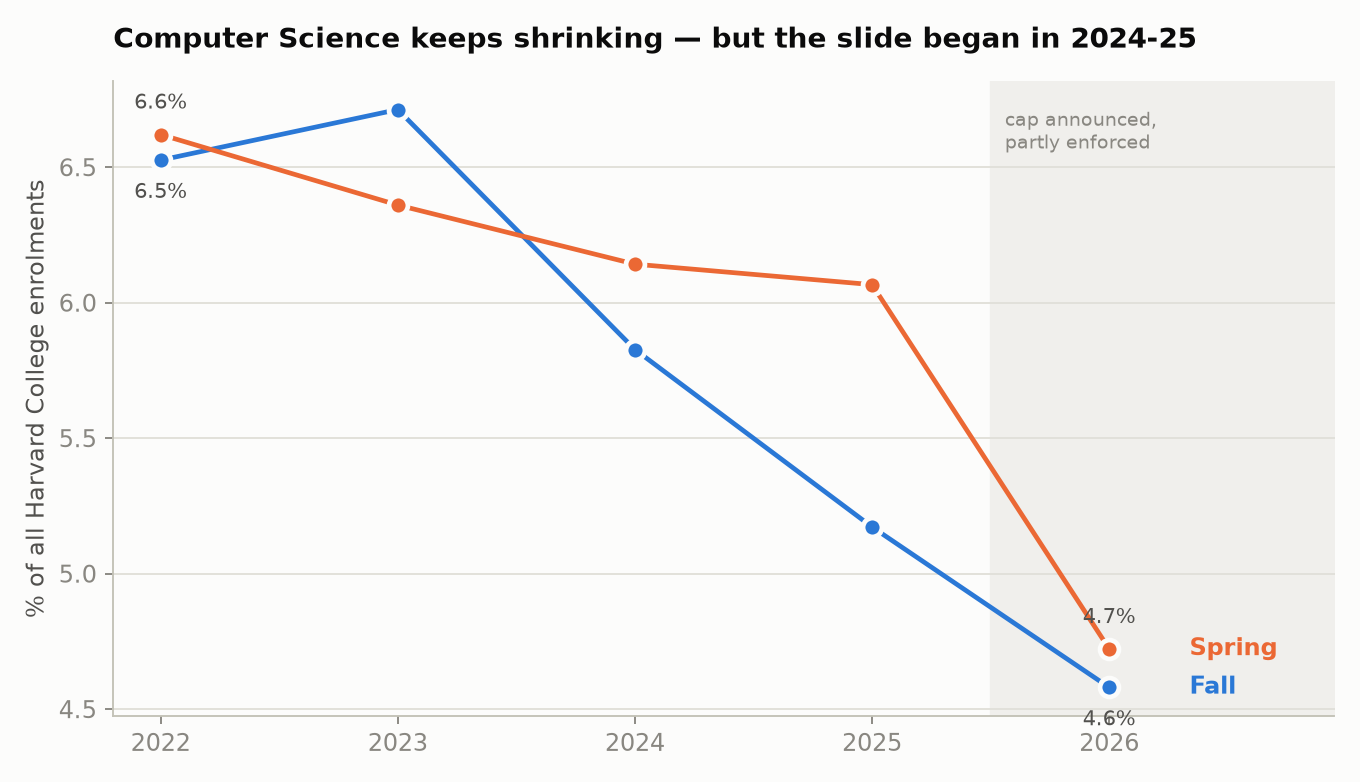

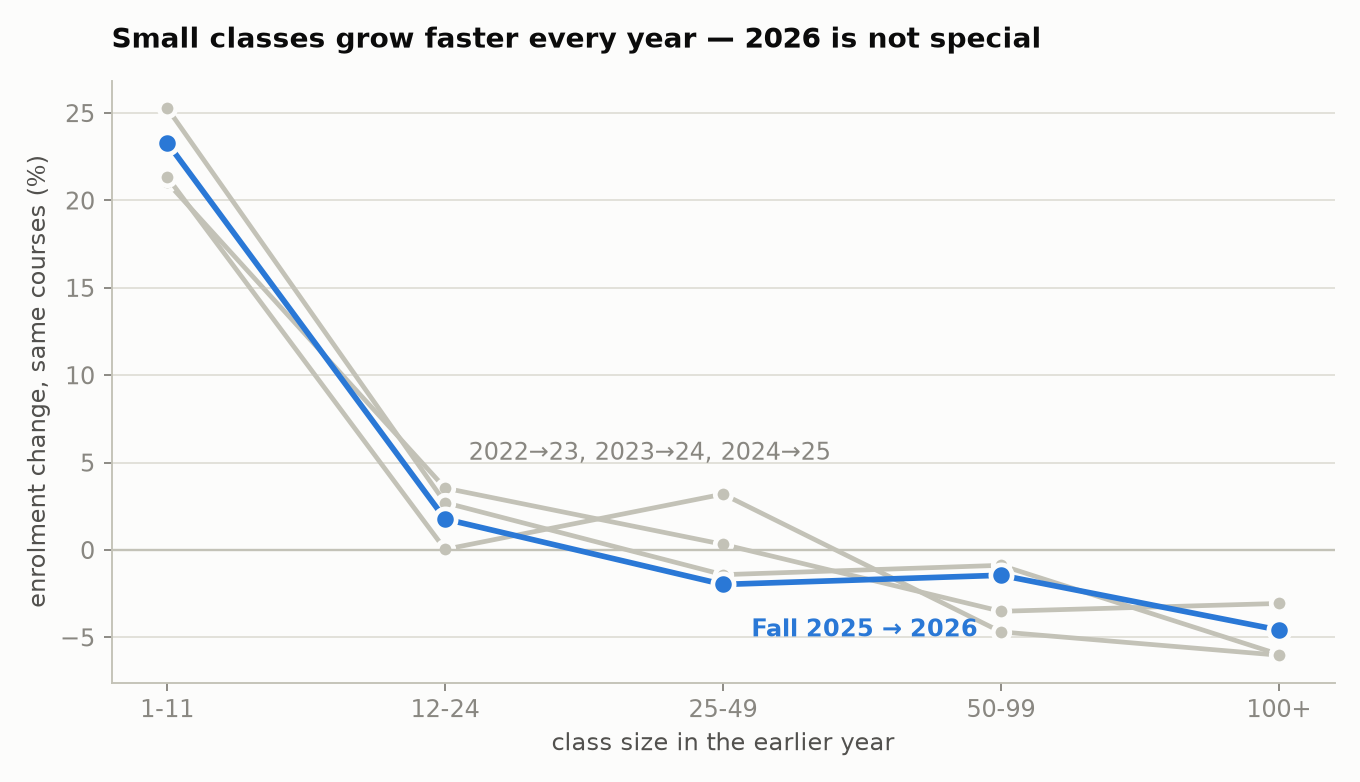

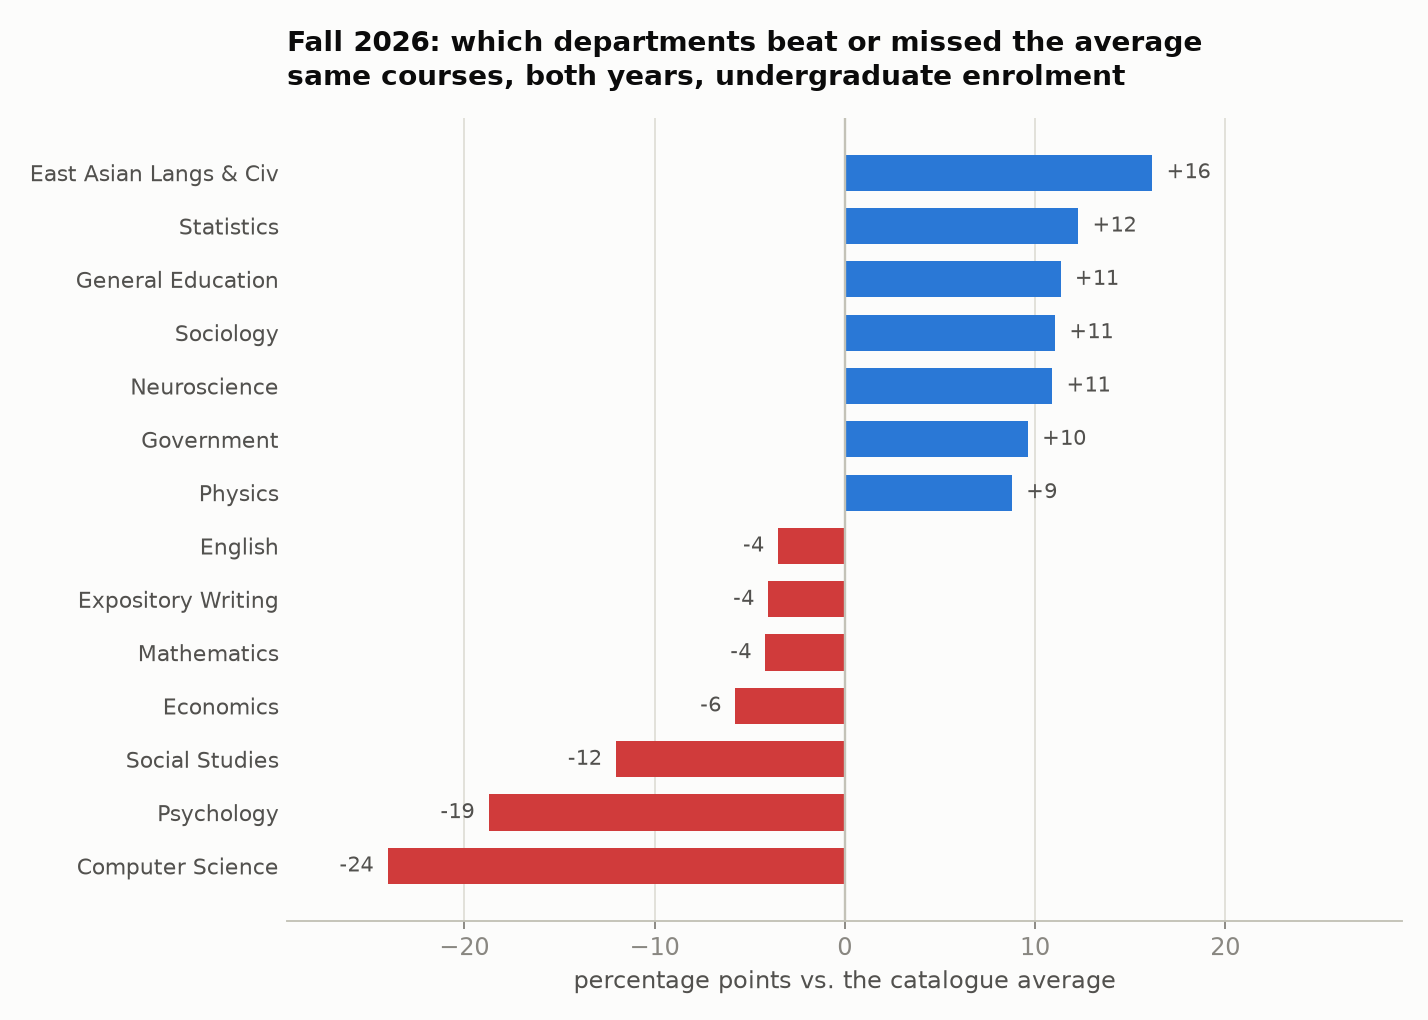

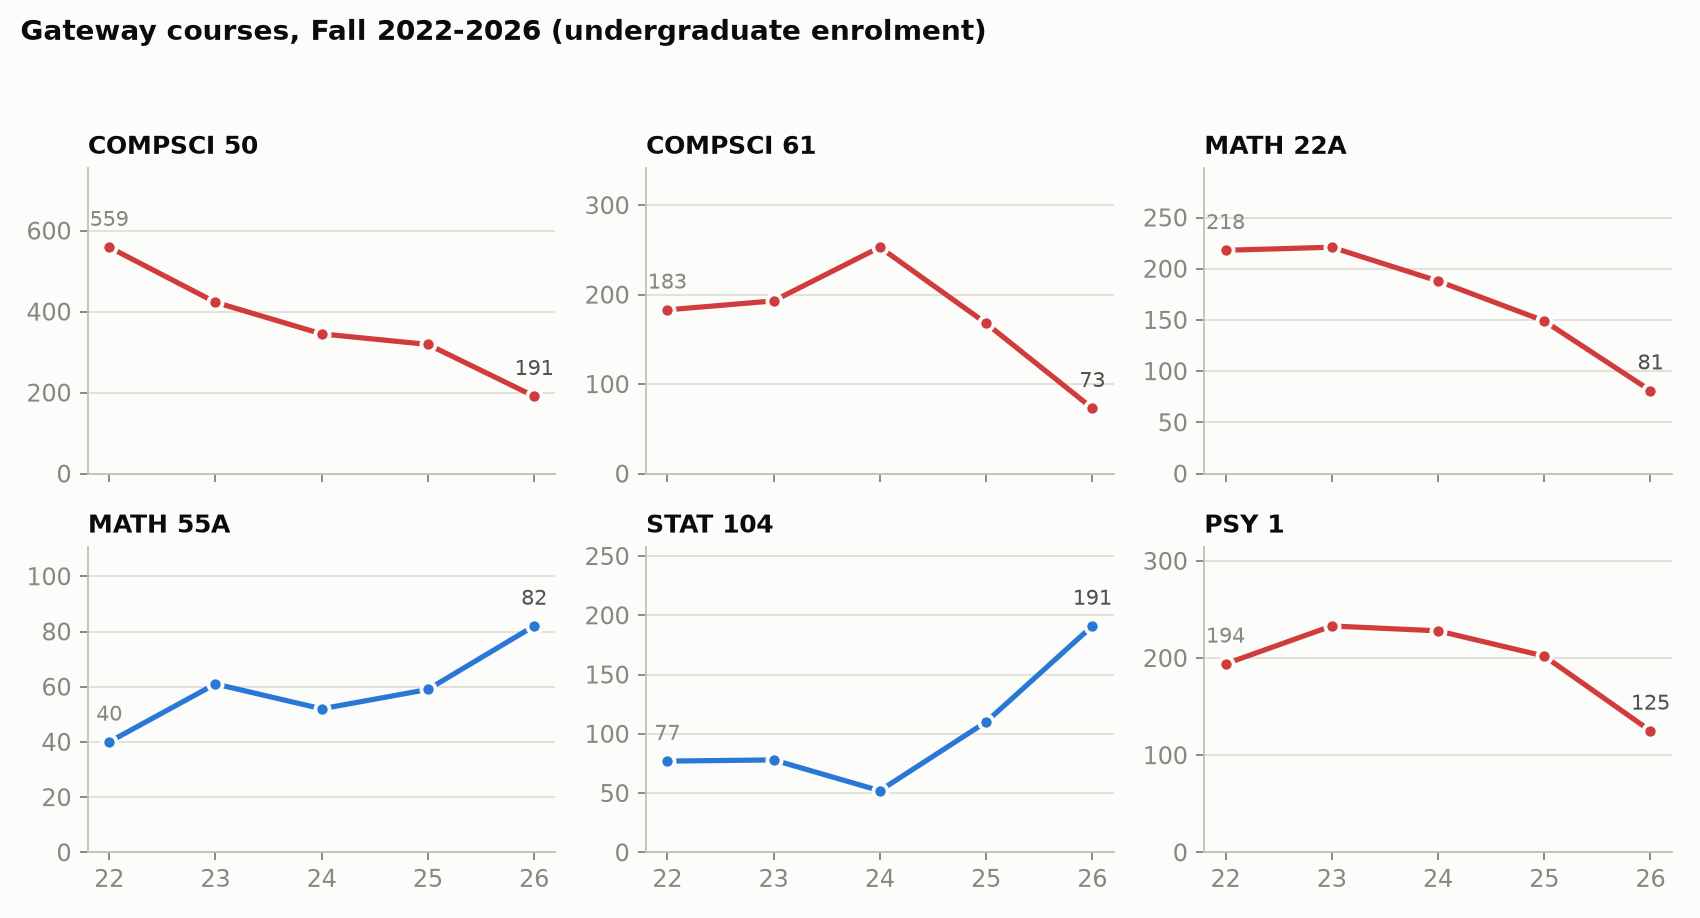

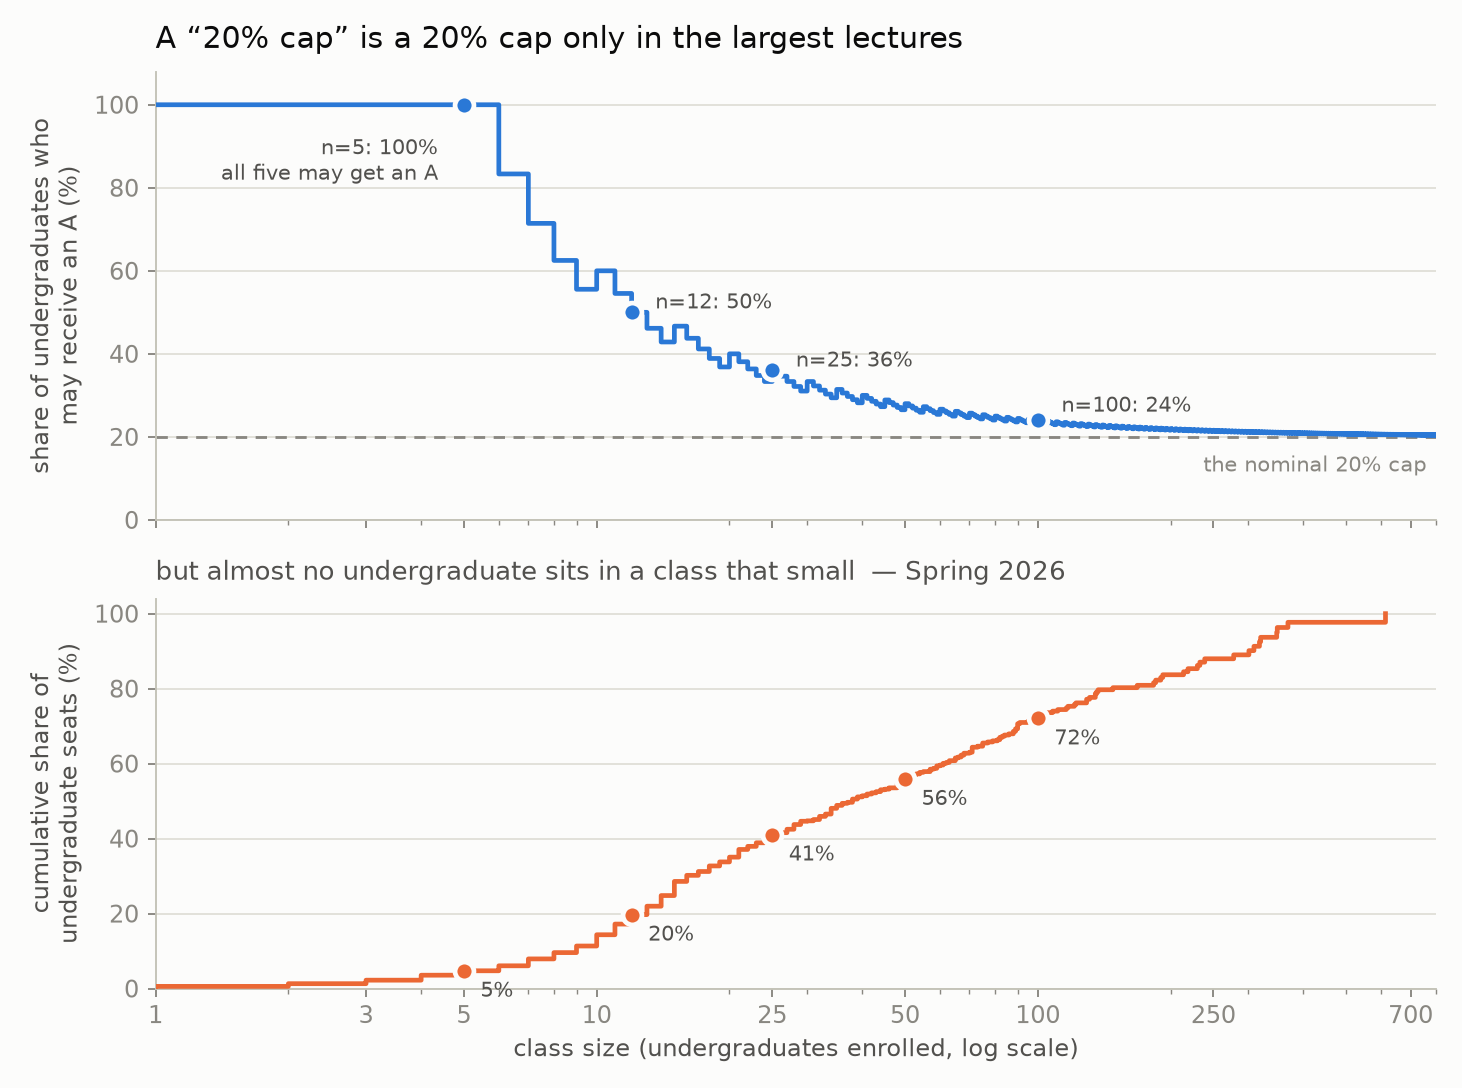

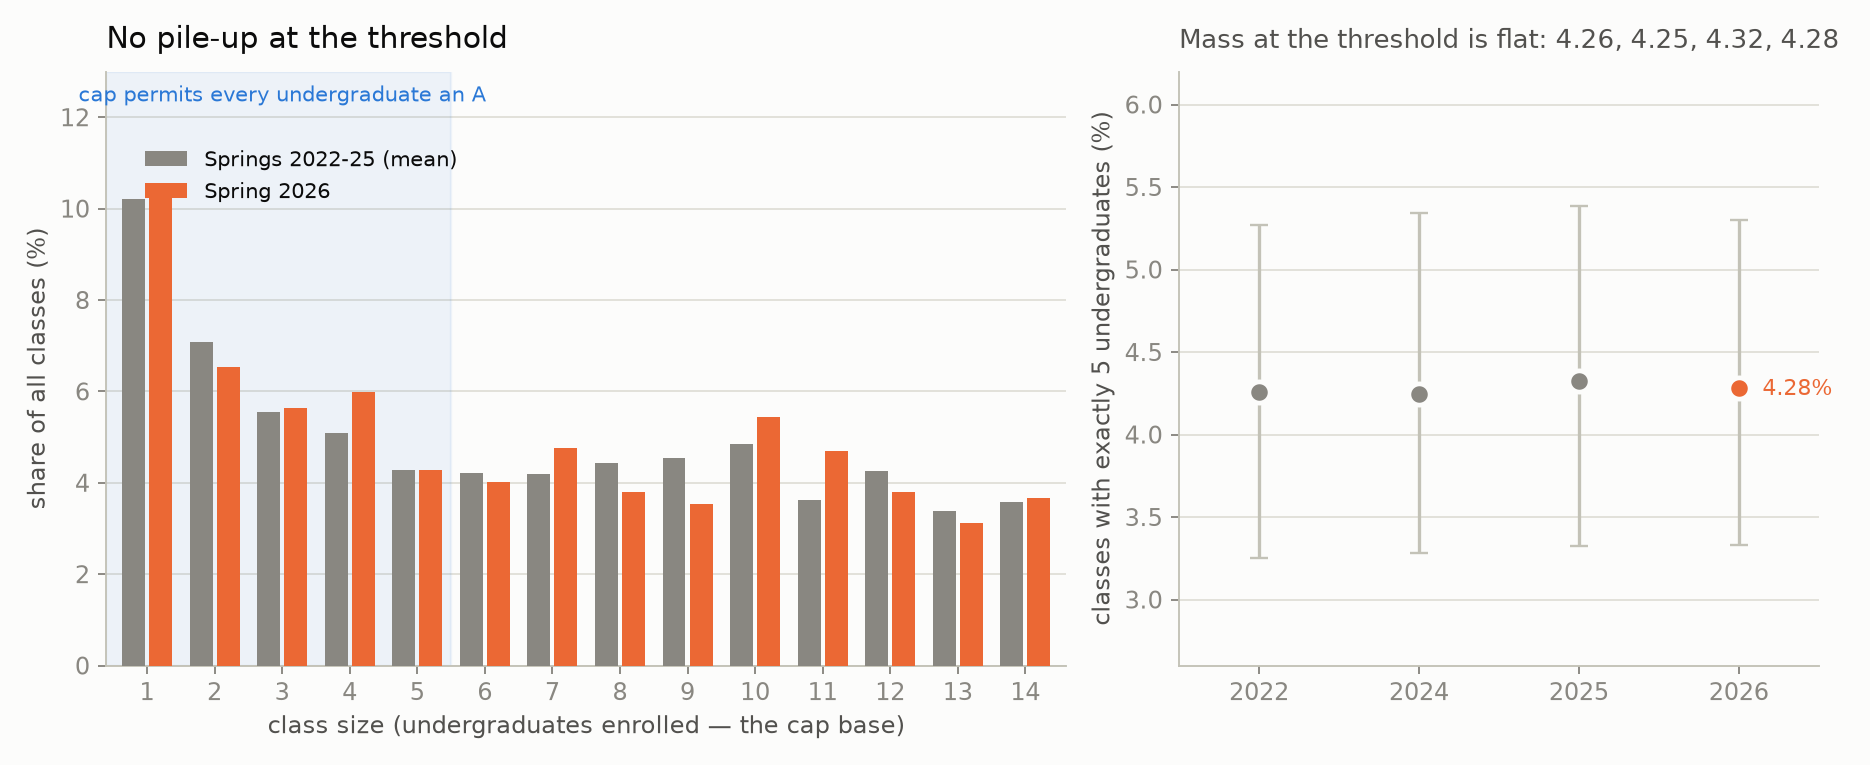

In [29]:
from IPython.display import Image, display
for f in ["fig1_cs_share.png", "fig2_small_class_placebo.png",
          "fig3_dept_movers.png", "fig4_gateway_courses.png",
          "fig5_cap_curve.png", "fig6_bunching.png"]:
    display(Image(f))

## 11. Findings

### Verdict on each hypothesis

| # | Hypothesis | Verdict | Evidence |
|---|---|---|---|
| 1 | Gen Ed stacking | **Not supported** | Fall 2026 matched-course gap +12.7pp, but Fall 2022→23 was +18.7pp and Spring 2026 was −14.1pp. Gen Ed's share is still below Fall 2022-24. |
| 2 | Shift to seminars / small classes | **Not supported** (re-tested, §5.2) | No bunching at the `n=5` threshold where the cap stops binding: the share of classes sitting exactly there is 4.26/4.25/4.32/**4.28**% across four springs (+0.01pp, 95% CI [−1.17, +1.23]). Small-class seat shares sit on the pre-trend. Fall 2026 is unusable here — pulled on day 14 of term. |
| 3 | Taking harder courses | **Mixed, weakly against** | Math 55a at a window high (59→82), but Math 22a −46% and the quantitative core −5.6pp. |
| 4 | Fleeing to graduate courses | **Contradicted** | −2.4pp in Fall, +3.3pp in Spring, against +17.1pp in an ordinary year. Only ~6% of undergraduate enrolments are graduate-level at all. |
| 5 | Avoiding CS and cap-enforcing departments | **Real, but mistimed** | CS share 6.7% → 4.6%; CS50 559 → 191. The steepest drop was Fall 2024→25, before the proposal was public. |
| 6 | Pre-med and iconic courses | **Not a 2026 effect** | Pre-med's jump was Fall 2025 (+16.6pp), then +2.5pp. Iconic courses stable apart from CS50. |

### What did change in 2026

1. **Psychology**, −18.7pp against the catalogue (z = −3.2), driven by PSY 1 falling 202 → 125.
   The sharpest genuinely new break of Fall 2026.
2. **Economics** turned negative in *both* 2026 terms (−5.8pp Fall, −5.5pp Spring, z = −2.9)
   after two positive years. Ec 10a 747 → 672; Ec 1010a 334 → 245.
3. **The Mathematics barbell** — `MATH 22A` −46%, `MATH 55A` at a window high, `STAT 104` +74%.
   Students leaving the demanding-but-unglamorous middle in both directions. Nobody predicted
   this and it is the pattern most worth watching.
4. **Supply contracted**: 171 fewer sections than Fall 2025, the largest cut in the window, and
   Gen Ed ran on the fewest sections in five years while enrolling 10.6% more undergraduates.
5. **Winners**: Statistics +12.3pp, Government +9.6pp, Neuroscience +10.9pp, Sociology +11.1pp,
   Physics +8.8pp.
6. **The cap is far looser than its name** (§5.3). Applied to the real class-size
   distribution, "20% + 4" permits **~37% of undergraduate grades to be A's**, and leaves
   classes of five or fewer entirely unconstrained. Our registrar-data estimate brackets the
   committee's own published figure of "about 34%". The projected cut falls on lecture
   courses; the small-seminar experience is untouched.

### The honest bottom line

Five of the six student hypotheses do not survive a pre-trend baseline. The two largest real
movements — the CS collapse and the pre-med surge — both began **before** the cap was public,
which points at the national CS downturn and at pre-med cohort size rather than at grading policy.

What the data cannot do is separate a cap effect from everything else happening in 2026. There is
one treated term per season and no control group — no comparable school, no untreated set of
Harvard departments. The Mathematics barbell and the Economics reversal are the two patterns worth
carrying into the Fall 2027 data, when the cap binds everywhere and a real before/after exists.

### Reproducing this

```
Course Enrollment/
├── enrolment_cap_analysis.ipynb   this notebook
├── enrollment_lib.py              loader, alias maps, taxonomy
├── make_charts.py                 the four figures
├── verify.py                      independent re-computation of every headline number
├── archive/                       S22 F22 S23 F23 S24 F24, from the registrar archive
└── Class Enrollment Summary*.csv  the four 2025-26 files
```

`verify.py` re-derives the headline numbers from the raw CSVs with the standard-library `csv`
module, sharing no code with `enrollment_lib`. It reproduces all of them exactly.